# Deep learning classification from **skeleton features only**: MLP / LSTM / 1D-CNN / CNN+LSTM

## 1. Imports, seed, configuration

In [ ]:
import os, sys, json, zipfile, random, time, gc, pickle, warnings
from itertools import combinations
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8") 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.preprocessing import LabelEncoder, Normalizer
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

warnings.filterwarnings("ignore")

#Seed
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass
set_seed()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
print("Device:", DEVICE)

#Configuration
CKPT_DIR   = os.path.join(OUT_DIR, 'partA_dl_skeleton_cv5_ckpt')   # one checkpoint per model x fold 
N_CV_FOLDS = 5

# Preprocessing fitted inside every training fold
USE_RFE        = True      
RFE_N_FEATURES = 53        
RFE_MAX_ROWS   = None      

# Early stopping: ~20 % of the TRAINING participants of each fold are held out (stratified) to pick the best epoch.
# The evaluation fold is never used for early stopping or checkpoint selection.
INNER_VAL_FRAC = 0.2

SEQ_LEN = 20               

# Per-model hyper-parameters
CFG = {
    'MLP':      dict(kind='tabular',  lr=1e-3, wd=1e-4, epochs=150, patience=20, batch=32, lam=0.3),
    'LSTM':     dict(kind='sequence', lr=1e-3, wd=1e-4, epochs=150, patience=20, batch=8,  lam=0.3),
    '1D-CNN':   dict(kind='sequence', lr=1e-3, wd=1e-4, epochs=150, patience=20, batch=8,  lam=0.3),
    'CNN+LSTM': dict(kind='sequence', lr=1e-3, wd=1e-4, epochs=150, patience=20, batch=8,  lam=0.3),
}
# Set lam=0.0 for a purely classification-trained model

MLP_HIDDEN_DIMS, MLP_DROPOUT = [128, 64], 0.4
LSTM_HIDDEN_SIZE, LSTM_NUM_LAYERS, LSTM_DROPOUT = 64, 1, 0.3
CNN_HIDDEN_CHANNELS, CNN_KERNEL_SIZE, CNN_DROPOUT = (64, 32), 3, 0.3
CNNLSTM_CONV_CHANNELS, CNNLSTM_KERNEL_SIZE, CNNLSTM_LSTM_HIDDEN, CNNLSTM_LSTM_LAYERS, CNNLSTM_DROPOUT = (64, 32), 3, 64, 1, 0.3


print(f"SEED={SEED} | folds={N_CV_FOLDS} | USE_RFE={USE_RFE} | early stopping on an inner split of the training participants")

Device: cuda
SEED=42 | folds=5 | USE_RFE=True | early stopping on an inner split of the training participants


## 2. Loading the dataset 


In [ ]:
KAGGLE_INPUT = '/kaggle/input'

def find_dream_root(base):
    
    best_root, best_count = None, 0
    for root, dirs, files in os.walk(base):
        json_subdirs = [
            d for d in dirs
            if any(f.endswith('.json')
                   for f in os.listdir(os.path.join(root, d))
                   if os.path.isfile(os.path.join(root, d, f)))
        ]
        if json_subdirs:
            total_json = sum(
                len([f for f in os.listdir(os.path.join(root, d)) if f.endswith('.json')])
                for d in json_subdirs
            )
            if total_json > best_count:
                best_root, best_count = root, total_json
    return best_root

dream_root = find_dream_root(KAGGLE_INPUT)
if dream_root is None:
    raise RuntimeError("DREAM dataset not found in /kaggle/input/. Add it to the notebook via 'Add Data'.")
extract_path = dream_root
print(f"DREAM dataset found in: {extract_path}")

DREAM dataset found in: /kaggle/input/datasets/rymjaballah/dream-dataset/snd1156-1-1/data/DREAM2020_SND1156-001-V1.0/DREAMdataset


## 3. Segmentation + feature extraction

In [ ]:
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs):
        return it

def safe_first(obj):
    if isinstance(obj, list):
        return obj[0] if obj else {}
    return obj if obj is not None else {}

#Constants feature extraction
SEGMENT_SIZE = 25

JOINTS = ['Head', 'ShoulderCenter', 'ShoulderLeft', 'ShoulderRight',
          'ElbowLeft', 'ElbowRight', 'WristLeft', 'WristRight',
          'HandLeft', 'HandRight']

JOINT_MAP_RAW = {
    'head':           'Head',
    'sholder_center': 'ShoulderCenter',
    'sholder_left':   'ShoulderLeft',
    'sholder_right':  'ShoulderRight',
    'elbow_left':     'ElbowLeft',
    'elbow_right':    'ElbowRight',
    'wrist_left':     'WristLeft',
    'wrist_right':    'WristRight',
    'hand_left':      'HandLeft',
    'hand_right':     'HandRight',
}

ANGLE_TRIPLETS = [
    ('Head',          'ShoulderCenter', 'ShoulderLeft'),
    ('Head',          'ShoulderCenter', 'ShoulderRight'),
    ('ShoulderLeft',  'ShoulderCenter', 'ShoulderRight'),
    ('ShoulderCenter','ShoulderLeft',   'ElbowLeft'),
    ('ShoulderCenter','ShoulderRight',  'ElbowRight'),
    ('ShoulderLeft',  'ElbowLeft',      'WristLeft'),
    ('ShoulderRight', 'ElbowRight',     'WristRight'),
    ('ElbowLeft',     'WristLeft',      'HandLeft'),
    ('ElbowRight',    'WristRight',     'HandRight'),
]

#Performance/Recovery Settings
N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))

MAX_IN_FLIGHT   = N_WORKERS * 4   # maximum number of files being processed at one time
CHECKPOINT_EVERY   = 200          # saves every 200 files
CHECKPOINT_SECONDS = 180          # And at least every 3 minutes, even if <200 files are created

CHECKPOINT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
CHECKPOINT_PKL = os.path.join(CHECKPOINT_DIR, 'feat_checkpoint.pkl')

print(f"CPU cores used for parallel processing : {N_WORKERS}")
print(f"Files being processed simultaneously (max) : {MAX_IN_FLIGHT}")

#Helpers

def assign_label(module, comm, inter):
    try:
        module = int(module)
    except (TypeError, ValueError):
        module = 1
    total = (comm or 0) + (inter or 0)
    cutoffs = {1: (7, 12), 2: (8, 12), 3: (7, 10)}
    asd_cut, aut_cut = cutoffs.get(module, (7, 12))
    if total >= aut_cut:
        return 'Autistic Disorder'
    elif total >= asd_cut:
        return 'ASD (AS, PDD)'
    return None

def euclidean_dist(A, B):
    return float(np.sqrt(np.sum((A - B) ** 2)))

def angle_between(P1, P2, P3):
    v1 = P1 - P2; v2 = P3 - P2
    cos_a = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9)
    return float(np.degrees(np.arccos(np.clip(cos_a, -1, 1))))

def to_float_array(lst):
    if not lst:
        return np.empty(0, dtype=float)
    return pd.to_numeric(pd.Series(lst), errors='coerce').to_numpy(dtype=float)

def build_xyz_array(d, keys):
    cols = [to_float_array(d.get(k, [])) for k in keys]
    n = max((len(c) for c in cols), default=0)
    if n == 0:
        return None
    out = np.full((n, len(keys)), np.nan)
    for i, c in enumerate(cols):
        out[:len(c), i] = c
    return out

def extract_features_arrays(seg_arrays, gaze_arrays, normative):
    feats = {}

    # Dv - 45 distances
    means = {j: seg_arrays[j].mean(axis=0) for j in JOINTS}
    for jA, jB in combinations(JOINTS, 2):
        feats[f'{jA}_{jB}_dist'] = euclidean_dist(means[jA], means[jB])

    # Wv - 9 angles
    for P1n, P2n, P3n in ANGLE_TRIPLETS:
        feats[f'{P1n}_{P2n}_{P3n}_angle'] = angle_between(means[P1n], means[P2n], means[P3n])

    # Dv - 8 gaze features
    vectors = {}
    for name in ['head', 'eye']:
        G_arr = gaze_arrays.get(name)
        if G_arr is not None and G_arr.shape[0] > 0:
            G = G_arr.mean(axis=0)
            mag = np.linalg.norm(G) + 1e-9
            feats[f'{name}_alpha'] = float(np.degrees(np.arccos(np.clip(G[0]/mag, -1, 1))))
            feats[f'{name}_beta']  = float(np.degrees(np.arccos(np.clip(G[1]/mag, -1, 1))))
            feats[f'{name}_gamma'] = float(np.degrees(np.arccos(np.clip(G[2]/mag, -1, 1))))
            vectors[name] = G
        else:
            feats[f'{name}_alpha'] = feats[f'{name}_beta'] = feats[f'{name}_gamma'] = np.nan

    if 'head' in vectors and 'eye' in vectors:
        H, E = vectors['head'], vectors['eye']
        H_mag = np.linalg.norm(H) + 1e-9
        E_mag = np.linalg.norm(E) + 1e-9
        cos_t = np.dot(E, H) / (E_mag * H_mag)
        theta = np.arccos(np.clip(cos_t, -1, 1))
        feats['gaze_angle_EH'] = float(np.degrees(theta))
        feats['gaze_zone_phi'] = float(np.degrees(np.arctan2(H_mag*np.sin(theta), E_mag+H_mag*np.cos(theta))))
    else:
        feats['gaze_angle_EH'] = feats['gaze_zone_phi'] = np.nan

    # Sv - 36 std features (30 skeleton + 6 gaze)
    for j in JOINTS:
        for ax_i, ax in enumerate(['x','y','z']):
            col = f'skeleton_{j.lower()}_{ax}'
            feats[f'{col}_std'] = float(seg_arrays[j][:, ax_i].std())
    for name in ['head', 'eye']:
        G_arr = gaze_arrays.get(name)
        for ax_i, ax in enumerate(['rx','ry','rz']):
            col = f'{name}_gaze_{ax}'
            feats[f'{col}_std'] = float(G_arr[:, ax_i].std()) if G_arr is not None else np.nan

    # Nav - 5
    feats.update(normative)
    return feats

# Main pipeline 

def process_json_file(fpath):
    with open(fpath) as f:
        data = json.load(f)

    p         = safe_first(data.get('participant', {}))
    ados      = data.get('ados', {})
    ados_data = ados.get('preTest', {}) if isinstance(ados, dict) else {}
    t         = data.get('task', {}) if isinstance(data.get('task'), dict) else {}

    comm   = ados_data.get('communication')
    inter  = ados_data.get('interaction')
    module = ados_data.get('module')
    label  = assign_label(module, comm, inter)
    if label is None:
        return []   

    pid        = p.get('id', p.get('child_id'))
    age_months = p.get('ageInMonths', p.get('age_months'))
    gender_raw = str(p.get('gender', 'unknown'))
    cond_raw   = data.get('condition', p.get('condition', 'SHT'))
    difficulty_raw = t.get('difficultyLevel', t.get('task_ability', 0))
    ability_raw= str(t.get('ability', t.get('task_ability', 'unknown')))
    ados_score = (comm or 0) + (inter or 0)

    skel = data.get('skeleton', {})
    hg   = data.get('head_gaze', {})
    eg   = data.get('eye_gaze',  {})

    joint_series = {}
    for raw_key, canon in JOINT_MAP_RAW.items():
        joint = skel.get(raw_key, {})
        joint_series[canon] = build_xyz_array(joint, ('x', 'y', 'z')) if isinstance(joint, dict) else None

    gaze_series = {
        'head': build_xyz_array(hg, ('rx', 'ry', 'rz')),
        'eye':  build_xyz_array(eg, ('rx', 'ry', 'rz')),
    }

    # Session length = maximum of available sets
    lengths = [a.shape[0] for a in joint_series.values() if a is not None]
    lengths += [a.shape[0] for a in gaze_series.values() if a is not None]
    if not lengths:
        return []
    n_frames = max(lengths)

    n_segs = n_frames // SEGMENT_SIZE
    if n_segs == 0:
        return []

    feats_list = []
    for i in range(n_segs):
        s, e = i * SEGMENT_SIZE, (i + 1) * SEGMENT_SIZE

        seg_arrays = {}
        for j in JOINTS:
            arr = joint_series[j]
            if arr is not None and s < arr.shape[0]:
                seg_arrays[j] = arr[s:min(e, arr.shape[0])]
                if len(seg_arrays[j]) < SEGMENT_SIZE:
                    pad = np.full((SEGMENT_SIZE - len(seg_arrays[j]), 3), np.nan)
                    seg_arrays[j] = np.vstack([seg_arrays[j], pad])
            else:
                seg_arrays[j] = np.full((SEGMENT_SIZE, 3), np.nan)

        seg_gaze = {}
        for name, arr in gaze_series.items():
            if arr is not None and s < arr.shape[0]:
                sliced = arr[s:min(e, arr.shape[0])]
                if len(sliced) < SEGMENT_SIZE:
                    pad = np.full((SEGMENT_SIZE - len(sliced), 3), np.nan)
                    sliced = np.vstack([sliced, pad])
                seg_gaze[name] = sliced
            else:
                seg_gaze[name] = None

        normative = {
            'participant_ageInMonths': age_months,
            'age_group':    0,
            'gender':       gender_raw,
            'task_ability': ability_raw,
            'task_difficulty': difficulty_raw,
        }

        feats = extract_features_arrays(seg_arrays, seg_gaze, normative)
        feats['participant_id'] = pid
        feats['label']          = label
        feats['ados_score']     = ados_score
        feats['age_months']     = age_months
        feats['condition']      = cond_raw

        feats_list.append(feats)

    return feats_list

# 1 all JSON files in the dataset

all_json_files = []
for user_dir in sorted(os.listdir(extract_path)):
    user_path = os.path.join(extract_path, user_dir)
    if not os.path.isdir(user_path):
        continue
    for fname in sorted(os.listdir(user_path)):
        if fname.endswith(".json"):
            all_json_files.append(os.path.join(user_path, fname))

print(f"JSON files detected: {len(all_json_files)}")

#2 Resuming from a checkpoint if the notebook has already been running

processed_set = set()
all_feats = []
if os.path.exists(CHECKPOINT_PKL):
    with open(CHECKPOINT_PKL, 'rb') as f:
        ck = pickle.load(f)
    processed_set = ck.get('processed', set())
    all_feats     = ck.get('feats', [])
    print(f"Checkpoint found -> {len(processed_set)} files already processed, "
          f"{len(all_feats)} segments already extracted. Resuming from there.")

remaining_files = [f for f in all_json_files if f not in processed_set]
print(f"Remaining files to process: {len(remaining_files)}")

def save_checkpoint():
    with open(CHECKPOINT_PKL, 'wb') as f:
        pickle.dump({'feats': all_feats, 'processed': processed_set}, f)

errors = []
n_done = len(processed_set)
t0 = time.time()

#3 Parallel processing with regular checkpoints

if remaining_files:
    file_iter = iter(remaining_files)
    last_ckpt_time = time.time()

    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        futures = {}
        #Prime the pool with at most MAX_IN_FLIGHT files
        for _ in range(min(MAX_IN_FLIGHT, len(remaining_files))):
            fp = next(file_iter)
            futures[ex.submit(process_json_file, fp)] = fp

        pbar = tqdm(total=len(remaining_files), desc="Extracting features")
        while futures:
            done, _ = wait(futures, return_when=FIRST_COMPLETED)
            for fut in done:
                fp = futures.pop(fut)
                try:
                    feats = fut.result()
                    all_feats.extend(feats)
                except Exception as e:
                    errors.append((fp, str(e)))
                processed_set.add(fp)
                n_done += 1
                pbar.update(1)

                # Resubmits a new file to keep the pool full
                try:
                    nf = next(file_iter)
                    futures[ex.submit(process_json_file, nf)] = nf
                except StopIteration:
                    pass

                now = time.time()
                if n_done % CHECKPOINT_EVERY == 0 or (now - last_ckpt_time) > CHECKPOINT_SECONDS:
                    save_checkpoint()
                    last_ckpt_time = now
                    elapsed = now - t0
                    print(f"[checkpoint] {n_done}/{len(all_json_files)} files processed "
                          f"({elapsed:.0f}s elapsed for this run)")
        pbar.close()

save_checkpoint()  # final checkpoint

feat_df = pd.DataFrame(all_feats)
gc.collect()

# Different encoding of categorical columns
feat_df['gender']       = LabelEncoder().fit_transform(feat_df['gender'].astype(str))
feat_df['task_ability'] = LabelEncoder().fit_transform(feat_df['task_ability'].astype(str))
feat_df['age_group']    = pd.cut(feat_df['age_months'], bins=5, labels=[0,1,2,3,4]).astype(int)
feat_df['participant_ageInMonths'] = feat_df['age_months']

print("=" * 60)
print(f"Files processed      : {n_done} / {len(all_json_files)}")
print(f"Total segments       : {len(feat_df)}")
print(f"Features per segment : {feat_df.shape[1]}")
print(f"Unique participants   : {feat_df['participant_id'].nunique()}")
print(f"Label distribution    : {feat_df['label'].value_counts().to_dict()}")
print(f"Errors                : {len(errors)}")
if errors:
    for p, e in errors[:5]:
        print(f"  {p} -> {e}")

display(feat_df.head())

CPU cores used for parallel processing : 3
Files being processed simultaneously (max) : 12
JSON files detected: 3121
Remaining files to process: 3121


Extracting features:   0%|          | 0/3121 [00:00<?, ?it/s]

[checkpoint] 200/3121 files processed (80s elapsed for this run)
[checkpoint] 400/3121 files processed (157s elapsed for this run)
[checkpoint] 600/3121 files processed (241s elapsed for this run)
[checkpoint] 800/3121 files processed (324s elapsed for this run)
[checkpoint] 1000/3121 files processed (398s elapsed for this run)
[checkpoint] 1200/3121 files processed (469s elapsed for this run)
[checkpoint] 1400/3121 files processed (544s elapsed for this run)
[checkpoint] 1600/3121 files processed (639s elapsed for this run)
[checkpoint] 1800/3121 files processed (727s elapsed for this run)
[checkpoint] 2000/3121 files processed (817s elapsed for this run)
[checkpoint] 2200/3121 files processed (899s elapsed for this run)
[checkpoint] 2400/3121 files processed (996s elapsed for this run)
[checkpoint] 2600/3121 files processed (1100s elapsed for this run)
[checkpoint] 2800/3121 files processed (1198s elapsed for this run)
[checkpoint] 3000/3121 files processed (1307s elapsed for this ru

,Head_ShoulderCenter_dist,Head_ShoulderLeft_dist,Head_ShoulderRight_dist,Head_ElbowLeft_dist,Head_ElbowRight_dist,Head_WristLeft_dist,Head_WristRight_dist,Head_HandLeft_dist,Head_HandRight_dist,ShoulderCenter_ShoulderLeft_dist,...,participant_ageInMonths,age_group,gender,task_ability,task_difficulty,participant_id,label,ados_score,age_months,condition
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET


## 4. Participants, skeleton-only features and 5 participant-grouped folds (same protocol as Part C)

In [ ]:
# 1. Exclude the 7 participants with the most missing data 
# The NaN rate is computed on ALL extracted columns so that exactly the same 54 participants are kept.
EXCLUDE = {'participant_id', 'label', 'ados_score', 'age_months', 'condition'}
ALL_COLS = [c for c in feat_df.columns if c not in EXCLUDE]
X_nan = feat_df[ALL_COLS].dropna(axis=1, how='all')
nan_rate_sorted = X_nan.isna().groupby(feat_df['participant_id']).mean().mean(axis=1).sort_values(ascending=False)

N_TO_EXCLUDE = 7
excluded_pids = nan_rate_sorted.head(N_TO_EXCLUDE).index.tolist()
print(f"Excluded participants (missing data): {len(excluded_pids)} -> {excluded_pids}")
EXPECTED_EXCLUDED = [31, 14, 15, 32, 44, 50, 30]          # Part C
if set(excluded_pids) != set(EXPECTED_EXCLUDED):
    print(f"WARNING: differs from Part C ({EXPECTED_EXCLUDED}). The folds will not be aligned with Part C.")

keep_mask = ~feat_df['participant_id'].isin(excluded_pids).values
feat_df_clean = feat_df.loc[keep_mask].reset_index(drop=True)
print(f"Remaining participants: {feat_df_clean['participant_id'].nunique()}  (Part C: 54)")

#2. Skeleton features ONLY 
JOINTS_SK = ['Head', 'ShoulderCenter', 'ShoulderLeft', 'ShoulderRight',
             'ElbowLeft', 'ElbowRight', 'WristLeft', 'WristRight', 'HandLeft', 'HandRight']
ANGLE_TRIPLETS_SK = [
    ('Head', 'ShoulderCenter', 'ShoulderLeft'), ('Head', 'ShoulderCenter', 'ShoulderRight'),
    ('ShoulderLeft', 'ShoulderCenter', 'ShoulderRight'),
    ('ShoulderCenter', 'ShoulderLeft', 'ElbowLeft'), ('ShoulderCenter', 'ShoulderRight', 'ElbowRight'),
    ('ShoulderLeft', 'ElbowLeft', 'WristLeft'), ('ShoulderRight', 'ElbowRight', 'WristRight'),
    ('ElbowLeft', 'WristLeft', 'HandLeft'), ('ElbowRight', 'WristRight', 'HandRight'),
]
SKELETON_FEATURES = [f'{a}_{b}_dist' for a, b in combinations(JOINTS_SK, 2)]
SKELETON_FEATURES += [f'{a}_{b}_{c}_angle' for a, b, c in ANGLE_TRIPLETS_SK]
SKELETON_FEATURES += [f'skeleton_{j.lower()}_{ax}_std' for j in JOINTS_SK for ax in ['x', 'y', 'z']]
missing = [c for c in SKELETON_FEATURES if c not in feat_df_clean.columns]
if missing:
    print(f"WARNING: skeleton features missing from feat_df: {missing}")
SKELETON_FEATURES = [c for c in SKELETON_FEATURES if c in feat_df_clean.columns]
print(f"Skeleton features used: {len(SKELETON_FEATURES)} (45 distances + 9 angles + 30 std). "
      f"Gaze and age / gender / task columns are NOT used.")
assert not any(('gaze' in c) or c.startswith(('head_', 'eye_')) for c in SKELETON_FEATURES)
assert not {'participant_ageInMonths', 'age_group', 'gender', 'task_ability', 'task_difficulty', 'ados_score', 'condition'} & set(SKELETON_FEATURES)

# 3. Arrays + 5 participant-grouped folds on all participants 
le = LabelEncoder()
y_all   = le.fit_transform(feat_df_clean['label']).astype(np.int64)       # 0 = 'ASD (AS, PDD)', 1 = 'AD'
r_all   = feat_df_clean['ados_score'].values.astype(np.float32)           # target of the auxiliary ADOS regression head
pid_all = feat_df_clean['participant_id'].values
X_skel  = feat_df_clean[SKELETON_FEATURES].values.astype(np.float32)      # NaN kept: imputed inside each fold
CLASS_NAMES = list(le.classes_)
assert len(CLASS_NAMES) == 2, "This notebook assumes a binary problem."
print("Classes:", dict(enumerate(CLASS_NAMES)), "| segments:", X_skel.shape[0])

SPLITS = list(StratifiedGroupKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=SEED)
              .split(X_skel, y_all, groups=pid_all))
EXPECTED_FOLDS = [(42, 12, 4, 8), (44, 10, 1, 9), (43, 11, 4, 7), (43, 11, 2, 9), (44, 10, 2, 8)]  
fold_ok = True
for k, (tr, va) in enumerate(SPLITS, 1):
    u, first = np.unique(pid_all[va], return_index=True)
    cnt = np.bincount(y_all[va][first], minlength=2)
    got = (len(np.unique(pid_all[tr])), len(u), int(cnt[0]), int(cnt[1]))
    fold_ok &= (k > len(EXPECTED_FOLDS)) or (got == EXPECTED_FOLDS[k - 1])
    assert not (set(pid_all[tr]) & set(pid_all[va])), "participant in both train and validation"
    assert cnt.min() > 0, f"fold {k}: validation fold misses a class"
    print(f"Fold {k}: train={got[0]} participants | val={got[1]} (ASD={got[2]}, Autistic Disorder={got[3]})")
print("Folds identical to Part C:", fold_ok)

Excluded participants (missing data): 7 -> [31, 14, 15, 32, 44, 50, 30]
Remaining participants: 54  (Part C: 54)
Skeleton features used: 84 (45 distances + 9 angles + 30 std). Gaze and age / gender / task columns are NOT used.
Classes: {0: 'ASD (AS, PDD)', 1: 'Autistic Disorder'} | segments: 913447
Fold 1: train=42 participants | val=12 (ASD=4, Autistic Disorder=8)
Fold 2: train=44 participants | val=10 (ASD=1, Autistic Disorder=9)
Fold 3: train=43 participants | val=11 (ASD=4, Autistic Disorder=7)
Fold 4: train=43 participants | val=11 (ASD=2, Autistic Disorder=9)
Fold 5: train=44 participants | val=10 (ASD=2, Autistic Disorder=8)
Folds identical to Part C: True


## 5. Data containers


In [ ]:
def build_participant_sequences(X, y_clf, y_reg, pids, seq_len=SEQ_LEN):
    
    unique_pids = pd.unique(pids)  
    sequences, lengths, y_clf_seq, y_reg_seq = [], [], [], []
    for pid in unique_pids:
        mask = pids == pid
        seg_feats = X[mask]
        n_seg = seg_feats.shape[0]
        if n_seg >= seq_len:
            seq = seg_feats[:seq_len]
            length = seq_len
        else:
            pad = np.zeros((seq_len - n_seg, X.shape[1]), dtype=np.float32)
            seq = np.vstack([seg_feats, pad])
            length = n_seg
        sequences.append(seq)
        lengths.append(length)
        y_clf_seq.append(y_clf[mask][0])
        y_reg_seq.append(y_reg[mask][0])
    return (np.asarray(sequences, dtype=np.float32), np.asarray(lengths),
            np.asarray(y_clf_seq), np.asarray(y_reg_seq), unique_pids)

def make_container(X, L, y, r, pid):
    return dict(X=X, L=np.asarray(L, dtype=np.int64), y=np.asarray(y), r=np.asarray(r, dtype=np.float32), pid=np.asarray(pid))

def subset(d, mask):
    return {k: v[mask] for k, v in d.items()}

## 6. Models

In [ ]:
class TabularMLPMultiTask(nn.Module):

    def __init__(self, n_features, n_classes, hidden_dims=MLP_HIDDEN_DIMS, dropout=MLP_DROPOUT):
        super().__init__()
        layers, in_dim = [], n_features
        for h in hidden_dims:
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            in_dim = h
        self.trunk     = nn.Sequential(*layers)
        self.asd_head  = nn.Linear(in_dim, n_classes)
        self.ados_head = nn.Linear(in_dim, 1)

    def forward(self, x, lengths=None):          
        z = self.trunk(x)
        return self.asd_head(z), self.ados_head(z).squeeze(-1)


class LSTMMultiTask(nn.Module):
    
    def __init__(self, n_features, n_classes, hidden_size=LSTM_HIDDEN_SIZE,
                 num_layers=LSTM_NUM_LAYERS, dropout=LSTM_DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden_size, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.asd_head  = nn.Linear(hidden_size, n_classes)
        self.ados_head = nn.Linear(hidden_size, 1)

    def forward(self, x, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        z = self.drop(h_n[-1])
        return self.asd_head(z), self.ados_head(z).squeeze(-1)


class TemporalCNNMultiTask(nn.Module):
    
    def __init__(self, n_features, n_classes, hidden_channels=CNN_HIDDEN_CHANNELS,
                 kernel_size=CNN_KERNEL_SIZE, dropout=CNN_DROPOUT):
        super().__init__()
        layers, in_ch = [], n_features
        for out_ch in hidden_channels:
            layers += [nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, padding=kernel_size // 2),
                       nn.BatchNorm1d(out_ch), nn.ReLU(), nn.Dropout(dropout)]
            in_ch = out_ch
        self.conv = nn.Sequential(*layers)
        self.asd_head  = nn.Linear(in_ch, n_classes)
        self.ados_head = nn.Linear(in_ch, 1)

    def forward(self, x, lengths):
        z = self.conv(x.transpose(1, 2))                                        # (B, C, T)
        idx = torch.arange(z.size(2), device=z.device).unsqueeze(0)
        mask = (idx < lengths.to(z.device).unsqueeze(1)).float().unsqueeze(1)   
        z_mean = (z * mask).sum(dim=2) / mask.sum(dim=2).clamp(min=1)
        return self.asd_head(z_mean), self.ados_head(z_mean).squeeze(-1)


class CNNLSTMMultiTask(nn.Module):
    
    def __init__(self, n_features, n_classes, conv_channels=CNNLSTM_CONV_CHANNELS,
                 kernel_size=CNNLSTM_KERNEL_SIZE, lstm_hidden=CNNLSTM_LSTM_HIDDEN,
                 lstm_layers=CNNLSTM_LSTM_LAYERS, dropout=CNNLSTM_DROPOUT):
        super().__init__()
        conv_layers, in_ch = [], n_features
        for out_ch in conv_channels:
            conv_layers += [nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, padding=kernel_size // 2),
                            nn.BatchNorm1d(out_ch), nn.ReLU(), nn.Dropout(dropout)]
            in_ch = out_ch
        self.conv = nn.Sequential(*conv_layers)
        self.lstm = nn.LSTM(in_ch, lstm_hidden, num_layers=lstm_layers, batch_first=True,
                            dropout=dropout if lstm_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.asd_head  = nn.Linear(lstm_hidden, n_classes)
        self.ados_head = nn.Linear(lstm_hidden, 1)

    def forward(self, x, lengths):
        z = self.conv(x.transpose(1, 2)).transpose(1, 2)                        # (B, T, C)
        packed = nn.utils.rnn.pack_padded_sequence(z, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        out = self.drop(h_n[-1])
        return self.asd_head(out), self.ados_head(out).squeeze(-1)


class MultiTaskLoss(nn.Module):
    
    def __init__(self, class_weights, lambda_ados):
        super().__init__()
        self.ce  = nn.CrossEntropyLoss(weight=class_weights)
        self.mse = nn.MSELoss()
        self.lam = lambda_ados

    def forward(self, logits_asd, pred_ados, y_asd, y_ados):
        loss_asd  = self.ce(logits_asd, y_asd)
        loss_ados = self.mse(pred_ados, y_ados)
        return loss_asd + self.lam * loss_ados, loss_asd, loss_ados


N_CLASSES = len(CLASS_NAMES)
BUILDERS = {
    'MLP':      lambda nf: TabularMLPMultiTask(nf, N_CLASSES),
    'LSTM':     lambda nf: LSTMMultiTask(nf, N_CLASSES),
    '1D-CNN':   lambda nf: TemporalCNNMultiTask(nf, N_CLASSES),
    'CNN+LSTM': lambda nf: CNNLSTMMultiTask(nf, N_CLASSES),
}

N_FEAT_MODEL = min(RFE_N_FEATURES, len(SKELETON_FEATURES)) if USE_RFE else len(SKELETON_FEATURES)
for n, b in BUILDERS.items():
    print(f"{n:9s}: {sum(p.numel() for p in b(N_FEAT_MODEL).parameters()):>8,d} parameters ({N_FEAT_MODEL} input features)")

MLP      :   15,747 parameters (53 input features)
LSTM     :   30,659 parameters (53 input features)
1D-CNN   :   16,707 parameters (53 input features)
CNN+LSTM :   41,891 parameters (53 input features)


## 7. Generic training / prediction


In [ ]:
def make_class_weights(y):
    counts = pd.Series(y).value_counts().sort_index()
    return torch.tensor(len(y) / (len(counts) * counts.values), dtype=torch.float32)

def inner_split(tr, seed=SEED, frac=INNER_VAL_FRAC):
    
    pids_u, first_idx = np.unique(tr['pid'], return_index=True)
    lab = tr['y'][first_idx]
    try:
        p_fit, p_val = train_test_split(pids_u, test_size=frac, stratify=lab, random_state=seed)
    except ValueError:
        p_fit, p_val = train_test_split(pids_u, test_size=frac, random_state=seed)
    return subset(tr, np.isin(tr['pid'], p_fit)), subset(tr, np.isin(tr['pid'], p_val))

def to_device(d):
    return (torch.tensor(d['X'], dtype=torch.float32, device=DEVICE),
            torch.tensor(d['L'], dtype=torch.long),                      # lengths stay on CPU (pack_padded_sequence)
            torch.tensor(d['y'], dtype=torch.long, device=DEVICE),
            torch.tensor(d['r'], dtype=torch.float32, device=DEVICE))

def train_model(name, tr, verbose=False):
   
    cfg = CFG[name]
    set_seed(SEED)                                            # every run is reproducible on its own
    fit, val = inner_split(tr)                                # early stopping on ~20 % of the training participants

    model = BUILDERS[name](fit['X'].shape[-1]).to(DEVICE)
    criterion = MultiTaskLoss(make_class_weights(fit['y']).to(DEVICE), cfg['lam'])
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])

    Xf, Lf, yf, rf = to_device(fit)
    Xv, Lv, yv, rv = to_device(val)
    n, bs = len(yf), cfg['batch']
    gen = torch.Generator().manual_seed(SEED)

    history = {'train_loss': [], 'val_loss': [], 'best_epoch': 0}
    best_val, best_state, wait_ = float('inf'), None, 0

    for epoch in range(cfg['epochs']):
        model.train()
        perm = torch.randperm(n, generator=gen)
        ep_loss = torch.zeros((), device=DEVICE)
        for s in range(0, n, bs):
            idx = perm[s:s + bs]
            if cfg['kind'] == 'tabular' and len(idx) < 2:     
                continue
            idx_d = idx.to(DEVICE)
            optimizer.zero_grad()
            logits, pred_o = model(Xf[idx_d], Lf[idx])
            loss, _, _ = criterion(logits, pred_o, yf[idx_d], rf[idx_d])
            loss.backward()
            optimizer.step()
            ep_loss += loss.detach() * len(idx)
        history['train_loss'].append(ep_loss.item() / n)

        model.eval()
        with torch.no_grad():
            lv, pv = model(Xv, Lv)
            val_loss, _, _ = criterion(lv, pv, yv, rv)
        history['val_loss'].append(val_loss.item())
        if verbose and (epoch + 1) % 10 == 0:
            print(f"    epoch {epoch+1}/{cfg['epochs']} — train={history['train_loss'][-1]:.4f}  val={val_loss.item():.4f}")

        if val_loss.item() < best_val:
            best_val, wait_, history['best_epoch'] = val_loss.item(), 0, epoch + 1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait_ += 1
            if wait_ >= cfg['patience']:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, history

@torch.no_grad()
def predict_proba(model, d, chunk=65536):
    model.eval()
    out = []
    for s in range(0, len(d['y']), chunk):
        X = torch.tensor(d['X'][s:s + chunk], dtype=torch.float32, device=DEVICE)
        L = torch.tensor(d['L'][s:s + chunk], dtype=torch.long)
        logits, _ = model(X, L)
        out.append(F.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(out)

## 8. Metrics 

In [ ]:
def compute_asd_metrics(y_true, y_pred, y_prob):
    
    return {
        "accuracy" : accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall"   : recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1"       : f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc"      : roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.0,
    }

def aggregate_by_participant(pids, y_true, y_prob):
  
    df = pd.DataFrame({'pid': pids, 'y_true': y_true, 'y_prob': y_prob})
    g = df.groupby('pid').agg(y_true=('y_true', 'first'), y_prob=('y_prob', 'mean')).reset_index()
    g['y_pred'] = (g['y_prob'] >= 0.5).astype(int)
    return compute_asd_metrics(g['y_true'].values, g['y_pred'].values, g['y_prob'].values), g

## 9. 5-fold cross-validation on the 54 participants (preprocessing fitted inside each fold)


In [ ]:
os.makedirs(CKPT_DIR, exist_ok=True)
def _ckpt(name, k):
    return os.path.join(CKPT_DIR, f"{name.replace('+', '_').replace(' ', '_').lower()}_fold{k}.pkl")

def preprocess_fold(tr_idx, va_idx):
    
    Xtr, Xva, ytr = X_skel[tr_idx], X_skel[va_idx], y_all[tr_idx]
    med = np.nan_to_num(np.nanmedian(Xtr, axis=0))                    # 1. median imputation (train only)
    Xtr = np.where(np.isnan(Xtr), med, Xtr).astype(np.float32)
    Xva = np.where(np.isnan(Xva), med, Xva).astype(np.float32)
    selected = list(SKELETON_FEATURES)
    if USE_RFE:                                                       # 2. RFE (train only)
        if RFE_MAX_ROWS is not None and len(Xtr) > RFE_MAX_ROWS:
            sub = np.random.RandomState(SEED).choice(len(Xtr), RFE_MAX_ROWS, replace=False)
        else:
            sub = slice(None)
        rfe = RFE(RandomForestClassifier(n_estimators=50, criterion='entropy', random_state=SEED, n_jobs=-1),
                  n_features_to_select=min(RFE_N_FEATURES, Xtr.shape[1]), step=5)
        rfe.fit(Xtr[sub], ytr[sub])
        Xtr, Xva = rfe.transform(Xtr), rfe.transform(Xva)
        selected = [SKELETON_FEATURES[i] for i, s in enumerate(rfe.support_) if s]
    norm = Normalizer(norm='l2')                                      # 3. L2 normalisation (train fit)
    Xtr, Xva = norm.fit_transform(Xtr).astype(np.float32), norm.transform(Xva).astype(np.float32)
    return Xtr, Xva, selected

results = {m: [] for m in CFG}
for k, (tr_idx, va_idx) in enumerate(SPLITS, 1):
    todo = [m for m in CFG if not os.path.exists(_ckpt(m, k))]
    if todo:
        t0 = time.time(); set_seed(SEED)
        Xtr, Xva, selected = preprocess_fold(tr_idx, va_idx)
        ytr, yva, rtr, rva = y_all[tr_idx], y_all[va_idx], r_all[tr_idx], r_all[va_idx]
        ptr, pva = pid_all[tr_idx], pid_all[va_idx]
        data_tr = {'tabular':  make_container(Xtr, np.ones(len(Xtr)), ytr, rtr, ptr),
                   'sequence': make_container(*build_participant_sequences(Xtr, ytr, rtr, ptr))}
        data_va = {'tabular':  make_container(Xva, np.ones(len(Xva)), yva, rva, pva),
                   'sequence': make_container(*build_participant_sequences(Xva, yva, rva, pva))}
        print(f"\n=== Fold {k}/{N_CV_FOLDS} | preprocessing in {time.time() - t0:.0f}s | {len(selected)} skeleton features "
              f"| train: {len(np.unique(ptr))} participants, val: {len(np.unique(pva))} participants ===")
    for name in CFG:
        path = _ckpt(name, k)
        if os.path.exists(path):
            with open(path, 'rb') as f:
                res = pickle.load(f)
            results[name].append(res)
            print(f"[{name}] fold {k} (resumed) | F1={res['pid']['f1']:.3f} AUC={res['pid']['auc']:.3f}")
            continue
        kind = CFG[name]['kind']
        t0 = time.time()
        model, hist = train_model(name, data_tr[kind])                    # early stopping on an inner split of the TRAIN participants
        prob = predict_proba(model, data_va[kind])[:, 1]
        dva = data_va[kind]
        pid_m, grouped = aggregate_by_participant(dva['pid'], dva['y'], prob)     # the metrics to report
        seg_m = compute_asd_metrics(dva['y'], (prob >= 0.5).astype(int), prob) if kind == 'tabular' else None  # MLP diagnostic only
        res = {'fold': k, 'n_participants': len(grouped), 'pid': pid_m, 'seg': seg_m, 'grouped': grouped,
               'best_epoch': hist['best_epoch'], 'n_epochs_run': len(hist['train_loss']), 'selected_features': selected}
        with open(path, 'wb') as f:
            pickle.dump(res, f)
        results[name].append(res)
        print(f"[{name}] fold {k}/{N_CV_FOLDS} | n_pid={len(grouped)} | Acc={pid_m['accuracy']:.3f} F1={pid_m['f1']:.3f} "
              f"AUC={pid_m['auc']:.3f} | best epoch {hist['best_epoch']}/{len(hist['train_loss'])} | {time.time() - t0:.0f}s")
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


=== Fold 1/5 | preprocessing in 2454s | 53 skeleton features | train: 42 participants, val: 12 participants ===
[MLP] fold 1/5 | n_pid=12 | Acc=0.750 F1=0.621 AUC=0.844 | best epoch 2/22 | 1549s
[LSTM] fold 1/5 | n_pid=12 | Acc=0.667 F1=0.400 AUC=0.531 | best epoch 53/73 | 3s
[1D-CNN] fold 1/5 | n_pid=12 | Acc=0.583 F1=0.368 AUC=0.438 | best epoch 77/97 | 4s
[CNN+LSTM] fold 1/5 | n_pid=12 | Acc=0.667 F1=0.400 AUC=0.625 | best epoch 62/82 | 3s

=== Fold 2/5 | preprocessing in 2536s | 53 skeleton features | train: 44 participants, val: 10 participants ===
[MLP] fold 2/5 | n_pid=10 | Acc=0.800 F1=0.444 AUC=0.556 | best epoch 4/24 | 1751s
[LSTM] fold 2/5 | n_pid=10 | Acc=0.900 F1=0.474 AUC=0.000 | best epoch 80/100 | 3s
[1D-CNN] fold 2/5 | n_pid=10 | Acc=0.700 F1=0.412 AUC=0.333 | best epoch 140/150 | 3s
[CNN+LSTM] fold 2/5 | n_pid=10 | Acc=0.900 F1=0.474 AUC=1.000 | best epoch 85/105 | 4s

=== Fold 3/5 | preprocessing in 2468s | 53 skeleton features | train: 43 participants, val: 11 part

## 10. Final comparison 

In [10]:
CLF_METRICS = ['accuracy', 'precision', 'recall', 'f1', 'auc']

mean, std, per_fold = {}, {}, {}
for name, folds in results.items():
    d = pd.DataFrame([{**f['pid'], 'fold': f['fold']} for f in folds]).set_index('fold')
    per_fold[name] = d
    mean[name], std[name] = d[CLF_METRICS].mean(), d[CLF_METRICS].std(ddof=1)
mean, std = pd.DataFrame(mean).T, pd.DataFrame(std).T
table = mean.apply(lambda c: c.map(lambda v: f"{v:.3f}")) + " ± " + std.apply(lambda c: c.map(lambda v: f"{v:.3f}"))

print("=" * 90)
print("  CLASSIFICATION — PARTICIPANT LEVEL (to report), macro metrics, mean ± std over 5 folds, 54 participants")
print("=" * 90)
display(table.sort_values('f1', ascending=False))
print("\nPer-fold participant-level metrics:")
for name, d in per_fold.items():
    print(f"\n{name}"); display(d.round(3))

mlp_seg = pd.DataFrame([{**f['seg'], 'fold': f['fold']} for f in results['MLP']]).set_index('fold')
print("\nMLP at segment level (diagnostic only — NOT the evaluation protocol):")
display((mlp_seg[CLF_METRICS].mean().map('{:.3f}'.format) + ' ± ' + mlp_seg[CLF_METRICS].std(ddof=1).map('{:.3f}'.format)).to_frame('mean ± std').T)

print("\nBest epoch per fold (early stopping on the inner split of the training participants):")
print({n: [f['best_epoch'] for f in folds] for n, folds in results.items()})

pd.concat({'mean': mean, 'std': std}, axis=1).to_csv(os.path.join(OUT_DIR, 'partA_dl_skeleton_cv5_summary_participant.csv'))
def tag(s): return s.replace(' ', '_').replace('(', '').replace(')', '').replace('+', '_').lower()
for name, d in per_fold.items():
    d.to_csv(os.path.join(OUT_DIR, f"partA_dl_skeleton_cv5_folds_{tag(name)}.csv"))
print("\nCSV files saved in", OUT_DIR)
print("Reminder: only 54 participants (13 in the minority class), 9-12 per validation fold — one participant moves "
      "a class recall by ~8-100 points; compare models using the fold-to-fold std, not small gaps.")

  CLASSIFICATION — PARTICIPANT LEVEL (to report), macro metrics, mean ± std over 5 folds, 54 participants


,accuracy,precision,recall,f1,auc
MLP,0.781 ± 0.097,0.706 ± 0.267,0.592 ± 0.169,0.606 ± 0.187,0.671 ± 0.283
1D-CNN,0.706 ± 0.084,0.528 ± 0.228,0.531 ± 0.156,0.515 ± 0.171,0.447 ± 0.165
LSTM,0.764 ± 0.110,0.382 ± 0.055,0.500 ± 0.000,0.431 ± 0.036,0.502 ± 0.302
CNN+LSTM,0.764 ± 0.110,0.382 ± 0.055,0.500 ± 0.000,0.431 ± 0.036,0.585 ± 0.250



Per-fold participant-level metrics:

MLP


,accuracy,precision,recall,f1,auc
fold,,,,,
1,0.750,0.864,0.625,0.621,0.844
2,0.800,0.444,0.444,0.444,0.556
3,0.818,0.889,0.750,0.771,0.857
4,0.636,0.389,0.389,0.389,0.222
5,0.900,0.944,0.750,0.804,0.875



LSTM


...


CNN+LSTM


,accuracy,precision,recall,f1,auc
fold,,,,,
1,0.667,0.333,0.5,0.400,0.625
2,0.900,0.450,0.5,0.474,1.000
3,0.636,0.318,0.5,0.389,0.411
4,0.818,0.409,0.5,0.450,0.389
5,0.800,0.400,0.5,0.444,0.500



MLP at segment level (diagnostic only — NOT the evaluation protocol):


,accuracy,precision,recall,f1,auc
mean ± std,0.655 ± 0.040,0.550 ± 0.058,0.547 ± 0.070,0.540 ± 0.073,0.556 ± 0.129



Best epoch per fold (early stopping on the inner split of the training participants):
{'MLP': [2, 4, 6, 3, 1], 'LSTM': [53, 80, 37, 66, 48], '1D-CNN': [77, 140, 115, 95, 94], 'CNN+LSTM': [62, 85, 45, 71, 53]}

CSV files saved in /kaggle/working
Reminder: only 54 participants (13 in the minority class), 9-12 per validation fold — one participant moves a class recall by ~8-100 points; compare models using the fold-to-fold std, not small gaps.


## 11. Confusion matrices and ROC curves 

MLP: sensitivity (recall Autistic Disorder) = 0.927 | specificity (recall ASD (AS, PDD)) = 0.308
LSTM: sensitivity (recall Autistic Disorder) = 1.000 | specificity (recall ASD (AS, PDD)) = 0.000
1D-CNN: sensitivity (recall Autistic Disorder) = 0.854 | specificity (recall ASD (AS, PDD)) = 0.231
CNN+LSTM: sensitivity (recall Autistic Disorder) = 1.000 | specificity (recall ASD (AS, PDD)) = 0.000


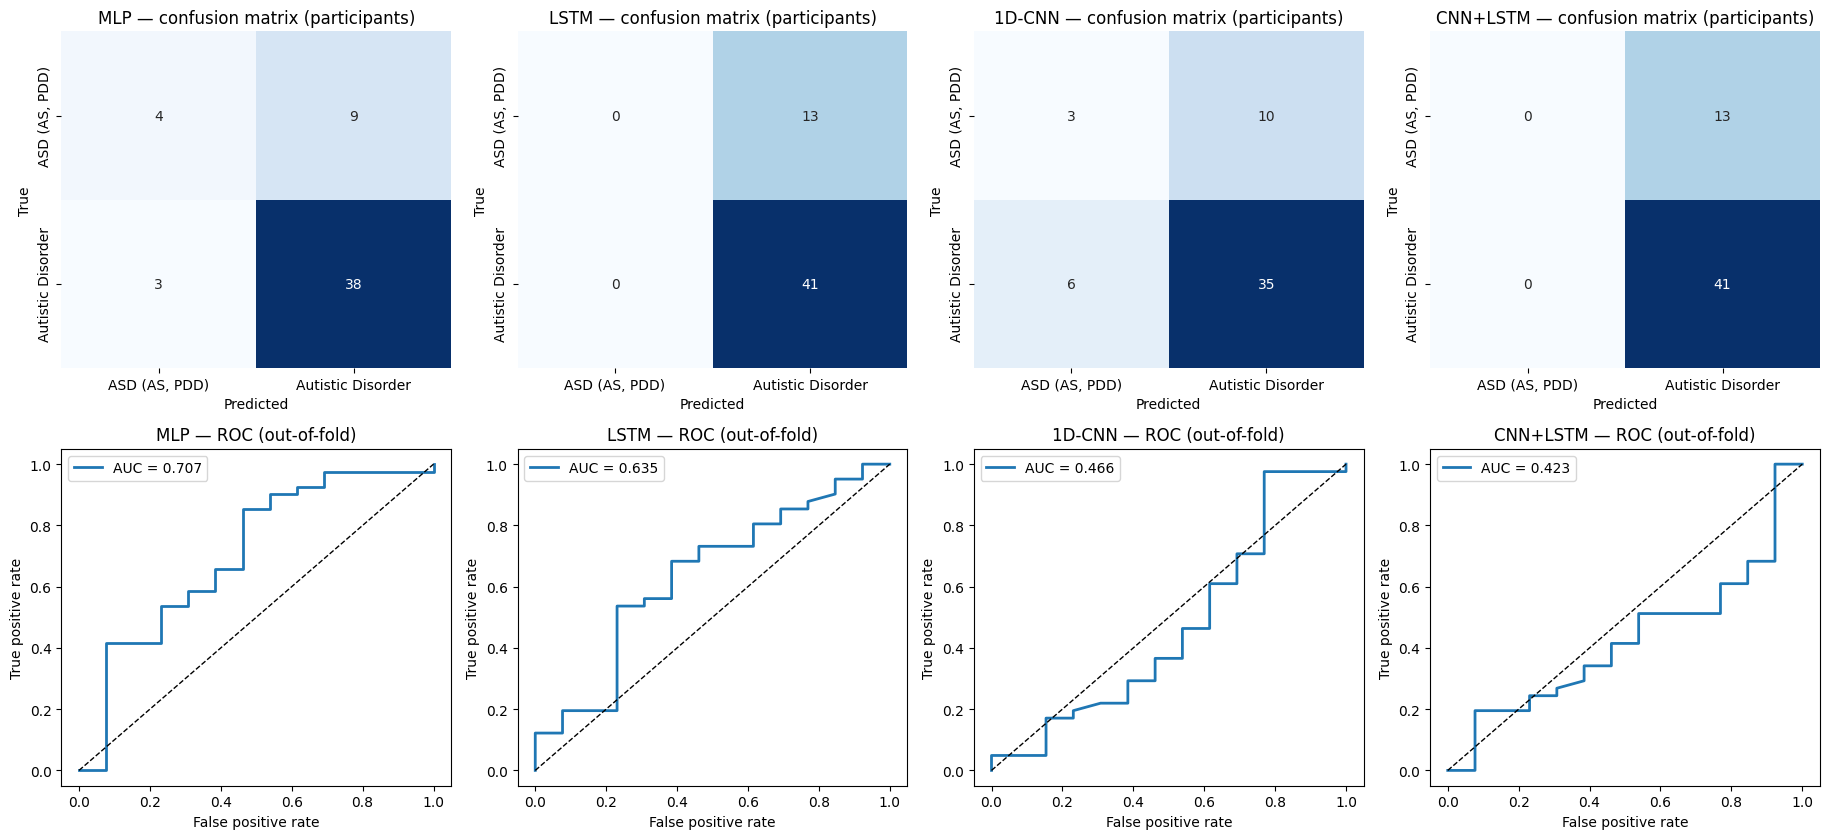

In [ ]:

fig, axes = plt.subplots(2, len(CFG), figsize=(4.6 * len(CFG), 8.5))
for j, name in enumerate(CFG):
    g = pd.concat([r['grouped'] for r in results[name]], ignore_index=True)
    assert g['pid'].is_unique and len(g) == len(np.unique(pid_all))
    cm = confusion_matrix(g['y_true'], g['y_pred'], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0, j],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axes[0, j].set_title(f"{name} — confusion matrix (participants)")
    axes[0, j].set_xlabel('Predicted'); axes[0, j].set_ylabel('True')
    fpr, tpr, _ = roc_curve(g['y_true'], g['y_prob'])
    axes[1, j].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(g['y_true'], g['y_prob']):.3f}")
    axes[1, j].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[1, j].set_title(f"{name} — ROC (out-of-fold)")
    axes[1, j].set_xlabel('False positive rate'); axes[1, j].set_ylabel('True positive rate'); axes[1, j].legend()
    sens = cm[1, 1] / max(cm[1].sum(), 1); spec = cm[0, 0] / max(cm[0].sum(), 1)
    print(f"{name}: sensitivity (recall {CLASS_NAMES[1]}) = {sens:.3f} | specificity (recall {CLASS_NAMES[0]}) = {spec:.3f}")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'partA_dl_skeleton_cv5_cm_roc.png'), dpi=150)
plt.show()